<a href="https://colab.research.google.com/github/vitorjensen/Python_para_Analise_de_Dados/blob/main/Projetos/Classificac%CC%A7a%CC%83o%20com%20Perceptron/Aplica%C3%A7%C3%A3o_do_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Importando bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report

In [ ]:
# Fazendo leitura do CSV
df = pd.read_csv('/content/drive/MyDrive/breast_cancer_wisconsin.csv')
display(df.head())
display(df.tail())

In [ ]:
# Verificando informações da base de dados
df.info()

In [ ]:
# Contagem de ocorrências das classes-alvo (Maligno ou Benigno)
contagem = df['diagnostico'].value_counts()
display(contagem)

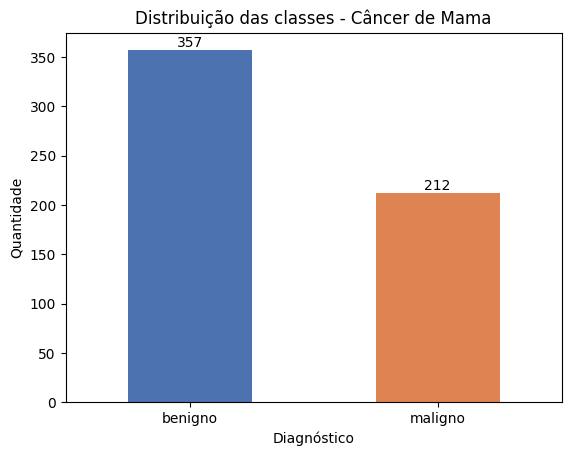

In [17]:
# Plotando gráfico para as classes contadas
ax = contagem.plot(kind='bar', color=['#4c72b0', '#dd8452'], rot=0)
ax.set_title('Distribuição das classes - Câncer de Mama')
ax.set_xlabel('Diagnóstico'); ax.set_ylabel('Quantidade')
for i, v in enumerate(contagem):
  ax.text(i, v + 3, str(v), ha='center')
plt.show()

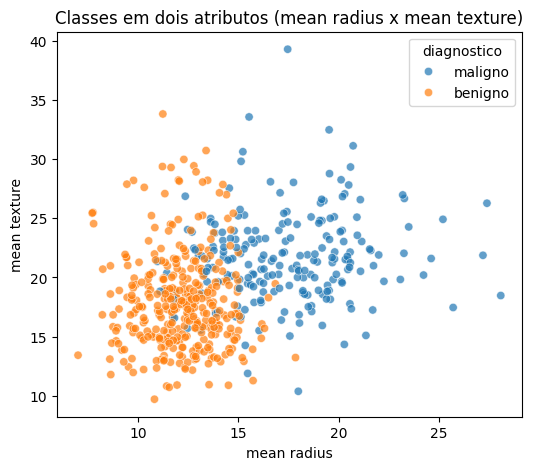

In [18]:
# Aplicando gráfico de dispersão

plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x='mean radius', y='mean texture', hue='diagnostico', alpha=0.7)
plt.title('Classes em dois atributos (mean radius x mean texture)')
plt.show()

In [ ]:
# Fazendo análise de correlação linear entre atributos numéricos

# Definindo colunas numéricas
df_copia = df.copy()
df_copia = df_copia.drop('target', axis=1)
df_copia['diagnostico'] = df_copia['diagnostico'].map({'benigno': 0, 'maligno': 1})
colunas_numericas = [coluna for coluna in df_copia.columns
                     if df_copia[coluna].dtype != 'object']

print(f"Temos um total de {len(colunas_numericas)} colunas numéricas.")

# Fazendo correlação
df_copia[colunas_numericas].corr()
#display(df_copia.sort_values(by='diagnostico'))


In [ ]:
df_copia.info()

In [52]:
# Aplicando Perceptron para classificação dos alvos: "Benigno" e "Maligno"

# Definindo variáveis X e Y com os dados necessários.
X = df_copia.drop(columns=['diagnostico'])
y = df_copia['diagnostico']

# Dividindo o dataset para treino (70%) tanto quanto para teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y
    )
print(f'Tamanho do treino: {X_train.shape[0]} amostras')
print(f'Tamanho do teste: {X_test.shape[0]} amostras')

Tamanho do treino: 398 amostras
Tamanho do teste: 171 amostras


In [56]:
# Normalização de dados para melhor performance
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [59]:
# Implementando o modelo Perceptron e treinando

modelo = Perceptron(max_iter=1000, eta0=1.0, random_state=42)
modelo.fit(X_train_s, y_train)

# Fazendo previsões e avaliando sua acurácia

y_pred = modelo.predict(X_test_s)
print(f'Acurácia no Treino: {modelo.score(X_train_s, y_train):.4f}')
print(f'Acurácia no Teste:  {accuracy_score(y_test, y_pred):.4f}')
print(f'Iterações até convergir: {modelo.n_iter_}')

Acurácia no Treino: 0.9774
Acurácia no Teste:  0.9532
Iterações até convergir: 11


In [60]:
# 1. Gerando o relatório detalhado de classificação
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['Benigno (0)', 'Maligno (1)']))

Relatório de Classificação:
              precision    recall  f1-score   support

 Benigno (0)       0.96      0.96      0.96       107
 Maligno (1)       0.94      0.94      0.94        64

    accuracy                           0.95       171
   macro avg       0.95      0.95      0.95       171
weighted avg       0.95      0.95      0.95       171



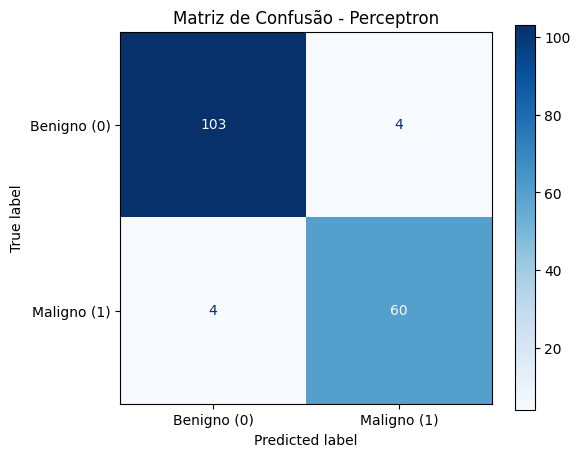

In [61]:
# 2. Plotando a Matriz de Confusão de forma visual
cm = confusion_matrix(y_test, y_pred, labels=modelo.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benigno (0)', 'Maligno (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusão - Perceptron')
plt.grid(False) # Remover linhas de grade automáticas do plot
plt.show()

In [64]:
# Extraindo informações de comparação com Perceptron para CSV
dados_conclusao = {
    'Instancia': range(1, len(y_test) + 1),
    'Gabarito': y_test,
    'Resposta Perceptron (Previsto)': y_pred,
    'Acertou?': [real == prev for real, prev in zip(y_test, y_pred)]
}

df = pd.DataFrame(dados_conclusao)
# 4. Exportar para um arquivo CSV
df.to_csv('resultado_perceptron.csv', index=False, sep=';', encoding='utf-8')

print("Arquivo 'resultado_perceptron.csv' gerado com sucesso!")

Arquivo 'resultado_perceptron.csv' gerado com sucesso!
